In [ ]:
# Notebook setup: locate the project and provide the source notebook's shared data context.
from pathlib import Path
import os
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "Project_machine_notebook.ipynb").is_file():
    if (PROJECT_ROOT.parent / "Project_machine_notebook.ipynb").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Open/run this notebook with the project folder as the working directory.")
DATA_DIR = PROJECT_ROOT / "Datasets"
os.chdir(DATA_DIR)
_df_raw = pd.read_csv("raw_football_dataset.csv")
_df_work = _df_raw.copy()
if "Expected goals (xG)" in _df_work and {"Shots on target", "Shots off target"}.issubset(_df_work.columns):
    _estimated_xg = _df_work["Shots on target"] * 0.3 + _df_work["Shots off target"] * 0.1
    _df_work.loc[_df_work["Expected goals (xG)"].eq(0), "Expected goals (xG)"] = _estimated_xg
_missing_limit = int(0.70 * len(_df_work))
_df_work = _df_work.drop(columns=_df_work.columns[_df_work.isna().sum().gt(_missing_limit)])
df2 = _df_work.dropna().drop_duplicates()
df = _df_raw.copy()
CLEANED_DATA_PATH = DATA_DIR / "cleaned_raw_football_dataset.csv"
df2.to_csv(CLEANED_DATA_PATH, index=False)


## **Manual Covariance and Correlation Calculation**
Here, we will manually calculate the covariance and Pearson correlation coefficient between Expected Goals (`xg`) and Actual Goals Scored (`goals_for`) to understand the mathematical relationship between these two variables.

In [31]:
a_mean = df2['Shots off target'].mean()
b_mean = df2['Goals for'].mean()

n_1 = len(df2) - 1
print(f"Mean of shots: {a_mean:.4f}, Mean of goals_for: {b_mean:.4f}")

s = sum([(a - a_mean) * (b - b_mean) for a, b in zip(df2['Shots off target'], df2['Goals for'])])
print(f"Sum of products of differences: {s:.4f}")

# Calculate Covariance
cov = s / n_1
print(f"Covariance: {cov:.4f}")

# Calculate Correlation Coefficient
corr = cov / (df2['Shots off target'].std() * df2['Goals for'].std())
print(f"Correlation: {corr:.4f}")

Mean of shots: 5.7981, Mean of goals_for: 1.4099
Sum of products of differences: 3230.9629
Covariance: 0.2981
Correlation: 0.0702


In [32]:
df2[['Shots off target', 'Goals for']]

,Shots off target,Goals for
0,10,1
1,6,4
2,10,4
3,7,0
4,15,0
...,...,...
10833,5,0
10834,6,4
10835,7,1
10836,2,4


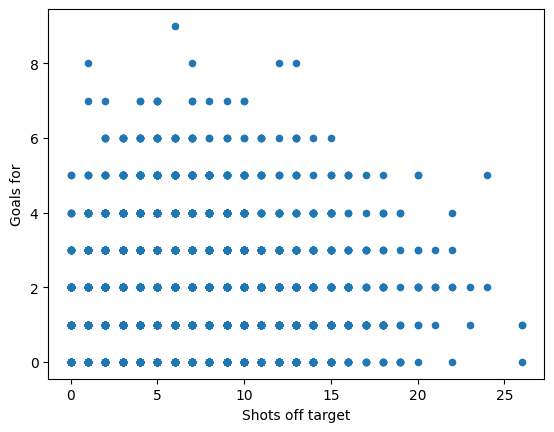

In [33]:
df2.plot.scatter(x = 'Shots off target', y = 'Goals for');
plt.show()

## **In The Automatic Correlation Matrix I Used The Orginal DF**

In [34]:
df['Fouls'] = df['Fouls'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Fouls'] = pd.to_numeric(df['Fouls'], errors='coerce').fillna(0)
Fouls_Corners_corr = df['Fouls'].corr(df['Corner kicks'])
print(f"Automatic Correlation between Fouls and Corners: {Fouls_Corners_corr:.4f}")


#here I will check the correlation between fouls and corners to see if there is any relationship between them but in the orginal df

Automatic Correlation between Fouls and Corners: -0.1117


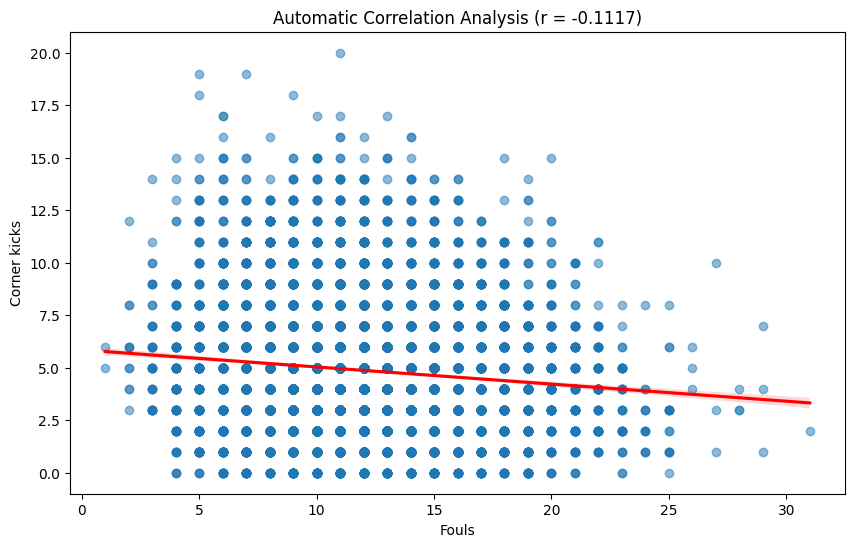

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Fouls', y='Corner kicks', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Automatic Correlation Analysis (r = {Fouls_Corners_corr:.4f})')
plt.show()

## **In The Automatic Correlation Matrix I Used The Cleaned DF**

In [36]:
df2['Fouls'] = df2['Fouls'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df2['Fouls'] = pd.to_numeric(df2['Fouls'], errors='coerce').fillna(0)
Fouls_Corners_corr = df2['Fouls'].corr(df2['Corner kicks'])
print(f"Automatic Correlation between Fouls and Corners: {Fouls_Corners_corr:.4f}")


#here I will check the correlation between fouls and corners to see if there is any relationship between them but in the cleaned df

Automatic Correlation between Fouls and Corners: -0.1117


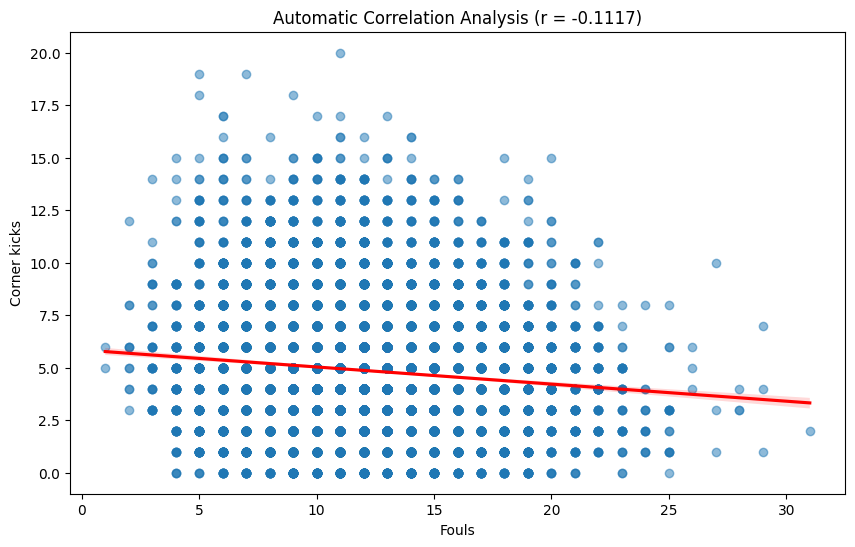

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.regplot(data=df2, x='Fouls', y='Corner kicks', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Automatic Correlation Analysis (r = {Fouls_Corners_corr:.4f})')
plt.show()

In [38]:
df2['Total shots'] = df2['Total shots'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df2['Total shots'] = pd.to_numeric(df2['Total shots'], errors='coerce').fillna(0)
Fouls_Corners_corr = df2['Total shots'].corr(df2['Corner kicks'])
print(f"Automatic Correlation between Shots and Corners: {Fouls_Corners_corr:.4f}")


#here I will check the correlation between shots and corners to see if there is any relationship between them but in the cleaned df

Automatic Correlation between Shots and Corners: 0.5503


## **Correlation Matrix and Target Feature Analysis**
Visualizing the correlation matrix for all numerical features and analyzing their relationship strength with our target variable (Goals For).

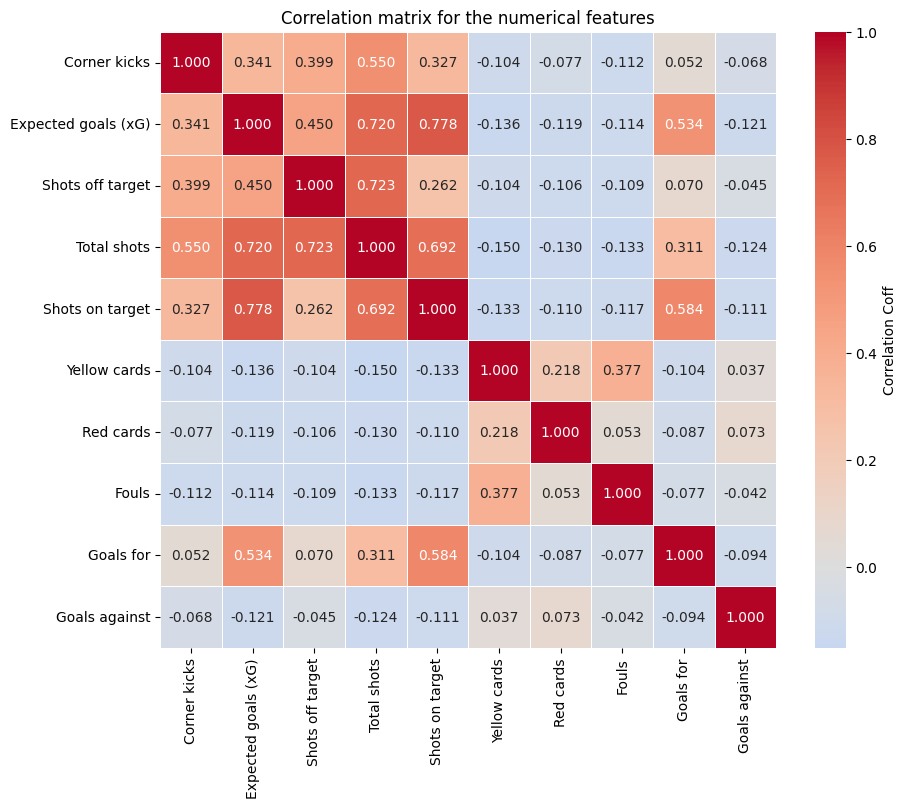

Correlation with target (goals_for)
Yellow cards: r = -0.1040 (Weak Negative correlation)
Goals against: r = -0.0940 (Weak Negative correlation)
Red cards: r = -0.0871 (Weak Negative correlation)
Fouls: r = -0.0767 (Weak Negative correlation)
Corner kicks: r = 0.0522 (Weak Positive correlation)
Shots off target: r = 0.0702 (Weak Positive correlation)
Total shots: r = 0.3109 (Moderate Positive correlation)
Expected goals (xG): r = 0.5336 (Strong Positive correlation)
Shots on target: r = 0.5836 (Strong Positive correlation)


In [39]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr();

plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', center=  0, fmt = '.3f', linewidths=0.5, square = True, cbar_kws={'label': 'Correlation Coff'})

plt.title("Correlation matrix for the numerical features")
plt.show()

print("Correlation with target (goals_for)")

# Changed 'Rating' to 'goals_for' as our target variable
rating_corr = correlation_matrix['Goals for'].drop('Goals for').sort_values(ascending=True)

for feature, corr in rating_corr.items():
    strength = 'Strong' if abs(corr) > 0.5 else 'Moderate' if abs(corr) > 0.3 else "Weak"
    direction = "Positive" if corr > 0 else "Negative";
    print(f"{feature}: r = {corr:.4f} ({strength} {direction} correlation)")

# **This is Yousef Nasr's Part**

## **Correlation Matrix and Target Feature Analysis for Cleaned dataset**
Visualizing the correlation matrix for all numerical features and analyzing their relationship strength with our target variable (Goals For).

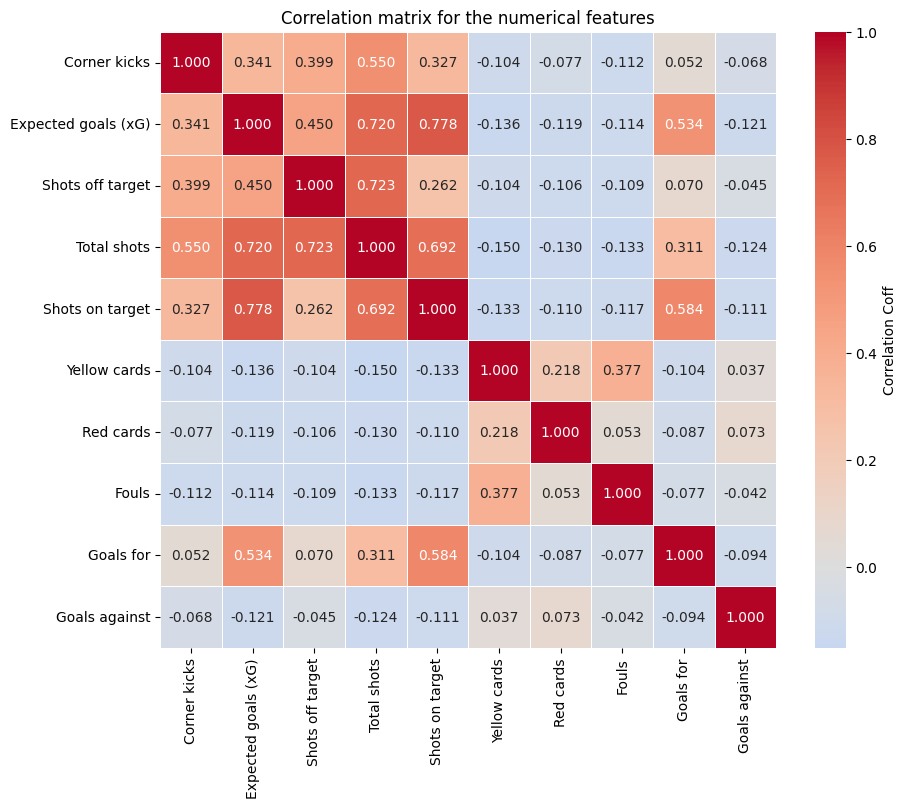

Correlation with target (goals_for)
Yellow cards: r = -0.1040 (Weak Negative correlation)
Goals against: r = -0.0940 (Weak Negative correlation)
Red cards: r = -0.0871 (Weak Negative correlation)
Fouls: r = -0.0767 (Weak Negative correlation)
Corner kicks: r = 0.0522 (Weak Positive correlation)
Shots off target: r = 0.0702 (Weak Positive correlation)
Total shots: r = 0.3109 (Moderate Positive correlation)
Expected goals (xG): r = 0.5336 (Strong Positive correlation)
Shots on target: r = 0.5836 (Strong Positive correlation)


In [40]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = df2.select_dtypes(include=[np.number]).columns
correlation_matrix = df2[numeric_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', center=  0, fmt = '.3f', linewidths=0.5, square = True, cbar_kws={'label': 'Correlation Coff'})

plt.title("Correlation matrix for the numerical features")
plt.show()

print("Correlation with target (goals_for)")

# Changed 'Rating' to 'goals_for' as our target variable
rating_corr = correlation_matrix['Goals for'].drop('Goals for').sort_values(ascending=True)

for feature, corr in rating_corr.items():
    strength = 'Strong' if abs(corr) > 0.5 else 'Moderate' if abs(corr) > 0.3 else "Weak"
    direction = "Positive" if corr > 0 else "Negative"
    print(f"{feature}: r = {corr:.4f} ({strength} {direction} correlation)")